# PlantGuard AI - Model training notebook

Trains the plant-disease classifier and **saves it into the project folder** so the web app can use it.

**What it does**
1. Finds the PlantVillage dataset (Kaggle `emmarex/plantdisease`) and removes exact duplicates
2. Builds a **leakage-safe split**: near-duplicate images (rotated/flipped copies of the same leaf) are grouped and kept in the same split
3. Compares 3 models (baseline CNN, MobileNetV2, EfficientNetB0) on the validation set, fine-tunes the best one
4. Evaluates **once** on the untouched test set (accuracy, macro precision/recall/F1, per-class, confusion matrix)
5. Calibrates confidence (temperature scaling) and saves everything to `model_weights/`

**Where to run**
* **Kaggle**: add the dataset, turn on *Internet* and a *GPU*, run all. At the end download `plantguard_model_files.zip` and unzip it into `plantguard-ai/model_weights/`.
* **Local** (run from `plantguard-ai/notebooks/`): put the extracted dataset under `plantguard-ai/datasets/` (or set env var `DATA_ROOT`). Files are saved to `plantguard-ai/model_weights/` directly.

First run with `QUICK_TEST = True` (a few minutes) to confirm everything works, then set it to `False` for the real run.

**Honesty rule:** the numbers in the app come from `metrics.json`, written from the real test set. Nothing is hard-coded.

## 1. Settings, imports and dataset discovery

In [13]:
import os, random, hashlib, json, time, shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, accuracy_score)
from sklearn.utils.class_weight import compute_class_weight
from scipy.optimize import minimize_scalar
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
try:
    from IPython.display import display
except ImportError:
    display = print

# ---------------- settings ----------------
SEED = 42
QUICK_TEST = True        # True = tiny subset, 1 epoch: only checks that the pipeline runs (results meaningless)
USE_PRETRAINED = True     # ImageNet weights need Internet (Kaggle: Settings -> Internet -> On)
GROUPED_SPLIT = True      # group near-duplicate images so they cannot leak across train/val/test
EPOCHS_HEAD = 1 if QUICK_TEST else 8        # training of the new classification head
EPOCHS_FINETUNE = 1 if QUICK_TEST else 8    # fine-tuning of the top backbone layers
FINETUNE_LAYERS = 30
IMG_SIZE, BATCH_SIZE = 224, 32
LOW_CONF_THRESHOLD = 0.60                  # below this calibrated confidence the app refuses to diagnose

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    PROJECT_DIR = Path("/kaggle/working")
    SEARCH_ROOTS = [Path("/kaggle/input")]
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    SEARCH_ROOTS = [Path(os.environ["DATA_ROOT"])] if "DATA_ROOT" in os.environ else []
    SEARCH_ROOTS += [PROJECT_DIR / "datasets", PROJECT_DIR / "data"]

OUT_DIR = PROJECT_DIR / "model_weights"      # <- the trained model is saved here
CKPT_DIR = OUT_DIR / "checkpoints"
OUT_DIR.mkdir(parents=True, exist_ok=True); CKPT_DIR.mkdir(parents=True, exist_ok=True)
print("TensorFlow", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))
print("Outputs will be saved to:", OUT_DIR)

# ---------------- find the dataset ----------------
CROPS = ["pepper", "potato", "tomato"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

candidates = []
for root_dir in SEARCH_ROOTS:
    if not root_dir.exists():
        continue
    for root, dirs, files in os.walk(root_dir):
        targets = [d for d in dirs if any(c in d.lower() for c in CROPS)]
        if len(targets) >= 3:
            n_img = 0
            for d in targets:
                try:
                    n_img += sum(1 for p in (Path(root) / d).iterdir()
                                 if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
                except OSError:
                    pass
            candidates.append({"path": Path(root), "target_classes": len(targets),
                               "images": n_img, "is_color": "color" in str(root).lower()})

if not candidates:
    raise RuntimeError("PlantVillage folder not found. Kaggle: attach the dataset. Local: extract it into "
                       f"{PROJECT_DIR / 'datasets'} or set the DATA_ROOT environment variable.")

candidate_df = (pd.DataFrame(candidates)
                .sort_values(["is_color", "images"], ascending=False).reset_index(drop=True))
print("Possible PlantVillage folders:")
display(candidate_df.head(10))
DATA_DIR = Path(candidate_df.iloc[0]["path"])
print("\nSELECTED DATASET:", DATA_DIR)

TensorFlow 2.21.0 | GPUs: 0
Outputs will be saved to: c:\Users\user\Music\plantguard-ai\plantguard-ai\model_weights
Possible PlantVillage folders:


,path,target_classes,images,is_color
0,c:\Users\user\Music\plantguard-ai\plantguard-a...,15,20638,False
1,c:\Users\user\Music\plantguard-ai\plantguard-a...,15,20638,False



SELECTED DATASET: c:\Users\user\Music\plantguard-ai\plantguard-ai\datasets\archive\PlantVillage


## 2. Dataset report and cleaning
Exact duplicates are removed by MD5 hash (and files that appear under two different labels are dropped).

In [16]:
def md5_hash(filepath):
    h = hashlib.md5()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

records, bad_images = [], 0
for class_folder in sorted(DATA_DIR.iterdir()):
    if not class_folder.is_dir() or not any(c in class_folder.name.lower() for c in CROPS):
        continue
    for image_path in sorted(class_folder.iterdir()):
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        try:
            with Image.open(image_path) as img:
                img.verify()
            records.append({"filepath": str(image_path), "class_name": class_folder.name,
                            "hash": md5_hash(image_path)})
        except Exception:
            bad_images += 1

df = pd.DataFrame(records)
n_before = len(df)

# files that exist under two different labels are ambiguous -> drop; keep one copy of identical files
conflicting = df.groupby("hash")["class_name"].nunique()
df = df[~df["hash"].isin(conflicting[conflicting > 1].index)]
df = df.drop_duplicates(subset="hash").reset_index(drop=True)

if QUICK_TEST:
    df = df.groupby("class_name", group_keys=False).head(60).reset_index(drop=True)
    print("QUICK_TEST: using a 60-images-per-class subset")

size_sample = df.sample(min(300, len(df)), random_state=SEED).filepath.map(lambda p: Image.open(p).size)
dataset_report = {
    "images_before_cleaning": n_before, "unreadable_images": bad_images, "images_after_cleaning": len(df),
    "n_classes": int(df.class_name.nunique()),
    "crops": sorted({c.split("_")[0] for c in df.class_name.unique()}),
    "class_counts": df.class_name.value_counts().sort_index().to_dict(),
    "imbalance_ratio_max_over_min": round(df.class_name.value_counts().max() / df.class_name.value_counts().min(), 1),
    "image_sizes_in_300_sample": {str(k): int(v) for k, v in size_sample.value_counts().items()},
}
print(f"Images before cleaning: {n_before} | unreadable: {bad_images} | after cleaning: {len(df)}")
print("Classes:", dataset_report["n_classes"], "| Crops:", dataset_report["crops"])
print("Imbalance ratio (largest/smallest class):", dataset_report["imbalance_ratio_max_over_min"])
print("Image sizes (300-image sample):", dataset_report["image_sizes_in_300_sample"])
display(df.class_name.value_counts().sort_index())

QUICK_TEST: using a 60-images-per-class subset
Images before cleaning: 20638 | unreadable: 0 | after cleaning: 900
Classes: 15 | Crops: ['Pepper', 'Potato', 'Tomato']
Imbalance ratio (largest/smallest class): 1.0
Image sizes (300-image sample): {'(256, 256)': 300}


class_name
Pepper__bell___Bacterial_spot                  60
Pepper__bell___healthy                         60
Potato___Early_blight                          60
Potato___Late_blight                           60
Potato___healthy                               60
Tomato_Bacterial_spot                          60
Tomato_Early_blight                            60
Tomato_Late_blight                             60
Tomato_Leaf_Mold                               60
Tomato_Septoria_leaf_spot                      60
Tomato_Spider_mites_Two_spotted_spider_mite    60
Tomato__Target_Spot                            60
Tomato__Tomato_YellowLeaf__Curl_Virus          60
Tomato__Tomato_mosaic_virus                    60
Tomato_healthy                                 60
Name: count, dtype: int64

## 3. Leakage-safe split (70 / 15 / 15)

PlantVillage contains several photos of the *same physical leaf* (rotated, flipped, re-cropped). A plain random split puts
some of them in training and some in test, which inflates the test accuracy. Here every image gets a tiny 16x16 grayscale fingerprint;
images whose fingerprints correlate strongly (under any of 8 rotations/flips) are put in the same **group**, and whole groups go to
one split only. The correlation threshold is chosen automatically so that no group becomes huge; check the printed group statistics.

In [17]:
MAX_GROUP = 40   # largest acceptable near-duplicate group

if GROUPED_SPLIT:
    # ---- 16x16 fingerprints under all 8 dihedral orientations ----
    V = np.zeros((len(df), 8, 256), np.float32)
    for i, p in enumerate(df.filepath):
        with Image.open(p) as im:
            im.draft("L", (64, 64))
            a = np.asarray(im.convert("L").resize((16, 16), Image.BILINEAR), np.float32)
        variants = [np.rot90(b, r) for b in (a, a[:, ::-1]) for r in range(4)]
        for k, v in enumerate(variants):
            v = v.reshape(-1) - v.mean()
            nrm = np.linalg.norm(v)
            V[i, k] = v / nrm if nrm > 1e-6 else v

    def group_labels(idx, thr, cap=3_000_000):
        """connected components of 'same leaf' pairs inside one class; None if the threshold is too loose"""
        n = len(idx)
        base, allv = V[idx, 0], V[idx].reshape(-1, 256)
        rows, cols, total = [], [], 0
        for s in range(0, n, 256):
            sim = (base[s:s + 256] @ allv.T).reshape(-1, n, 8).max(axis=2)
            ii, jj = np.nonzero(sim >= thr)
            total += len(ii)
            if total > cap:
                return None
            rows.append(ii + s); cols.append(jj)
        r, c = np.concatenate(rows), np.concatenate(cols)
        adj = coo_matrix((np.ones(len(r), np.int8), (r, c)), shape=(n, n))
        return connected_components(adj, directed=False)[1]

    chosen_thr, chosen = None, None
    for thr in (0.97, 0.975, 0.98, 0.985, 0.99, 0.995):
        labs, biggest, ok = {}, 0, True
        for cls, idx in df.groupby("class_name").indices.items():
            lab = group_labels(idx, thr)
            if lab is None:
                ok = False; break
            labs[cls] = lab
            biggest = max(biggest, int(np.bincount(lab).max()))
        print(f"threshold {thr}: " + (f"largest group = {biggest} images" if ok else "too many matches (too loose)"))
        if ok and biggest <= MAX_GROUP:
            chosen_thr, chosen = thr, labs
            break

    df["group"] = -1
    if chosen is None:
        print("WARNING: no threshold gave small groups; falling back to one group per image (near-duplicates may leak).")
        df["group"] = np.arange(len(df))
    else:
        offset = 0
        for cls, idx in df.groupby("class_name").indices.items():
            df.loc[df.index[idx], "group"] = chosen[cls] + offset
            offset += int(chosen[cls].max()) + 1
        sizes = df.groupby("group").size()
        print(f"\nUsing threshold {chosen_thr}: {len(sizes)} groups, {int((sizes > 1).sum())} groups with >1 image, "
              f"{int(sizes[sizes > 1].sum())} images share a group with another image")
    dataset_report["near_duplicate_threshold"] = chosen_thr

    # 20 stratified, group-aware folds -> 14 train / 3 val / 3 test  (=70/15/15)
    fold = np.full(len(df), -1)
    for k, (_, te) in enumerate(StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
                                .split(df, df["class_name"], df["group"])):
        fold[te] = k
    df["split"] = np.where(fold < 14, "train", np.where(fold < 17, "val", "test"))
    assert (df.groupby("group")["split"].nunique() == 1).all(), "a group leaked across splits"
    print("Group-leakage check: PASS")
else:
    tr, tmp = train_test_split(df, test_size=0.30, stratify=df["class_name"], random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=tmp["class_name"], random_state=SEED)
    df["split"] = "train"; df.loc[va.index, "split"] = "val"; df.loc[te.index, "split"] = "test"
    print("WARNING: plain stratified split - near-duplicates may leak across splits.")

train_df = df[df.split == "train"].copy()
val_df = df[df.split == "val"].copy()
test_df = df[df.split == "test"].copy()
assert set(train_df.hash).isdisjoint(val_df.hash) and set(train_df.hash).isdisjoint(test_df.hash) \
       and set(val_df.hash).isdisjoint(test_df.hash)
print("Exact-duplicate leakage check: PASS")
for name, part in (("Train", train_df), ("Validation", val_df), ("Test", test_df)):
    print(f"{name}: {len(part)} ({len(part) / len(df) * 100:.1f}%)")

split_by_class = df.groupby(["class_name", "split"]).size().unstack(fill_value=0)
display(split_by_class)
dataset_report["split_counts"] = {"train": len(train_df), "val": len(val_df), "test": len(test_df)}
dataset_report["grouped_split"] = GROUPED_SPLIT
train_df.to_csv(OUT_DIR / "train_split.csv", index=False)
val_df.to_csv(OUT_DIR / "validation_split.csv", index=False)
test_df.to_csv(OUT_DIR / "test_split.csv", index=False)

threshold 0.97: largest group = 1 images

Using threshold 0.97: 900 groups, 0 groups with >1 image, 0 images share a group with another image
Group-leakage check: PASS
Exact-duplicate leakage check: PASS
Train: 630 (70.0%)
Validation: 135 (15.0%)
Test: 135 (15.0%)


split,test,train,val
class_name,,,
Pepper__bell___Bacterial_spot,9,42,9
Pepper__bell___healthy,9,42,9
Potato___Early_blight,9,42,9
Potato___Late_blight,9,42,9
Potato___healthy,9,42,9
Tomato_Bacterial_spot,9,42,9
Tomato_Early_blight,9,42,9
Tomato_Late_blight,9,42,9
Tomato_Leaf_Mold,9,42,9


## 4. Data pipeline, augmentation and class weights

Number of classes: 15
0 Pepper__bell___Bacterial_spot
1 Pepper__bell___healthy
2 Potato___Early_blight
3 Potato___Late_blight
4 Potato___healthy
5 Tomato_Bacterial_spot
6 Tomato_Early_blight
7 Tomato_Late_blight
8 Tomato_Leaf_Mold
9 Tomato_Septoria_leaf_spot
10 Tomato_Spider_mites_Two_spotted_spider_mite
11 Tomato__Target_Spot
12 Tomato__Tomato_YellowLeaf__Curl_Virus
13 Tomato__Tomato_mosaic_virus
14 Tomato_healthy
Class weights: {'Pepper__bell___Bacterial_spot': 1.0, 'Pepper__bell___healthy': 1.0, 'Potato___Early_blight': 1.0, 'Potato___Late_blight': 1.0, 'Potato___healthy': 1.0, 'Tomato_Bacterial_spot': 1.0, 'Tomato_Early_blight': 1.0, 'Tomato_Late_blight': 1.0, 'Tomato_Leaf_Mold': 1.0, 'Tomato_Septoria_leaf_spot': 1.0, 'Tomato_Spider_mites_Two_spotted_spider_mite': 1.0, 'Tomato__Target_Spot': 1.0, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 1.0, 'Tomato__Tomato_mosaic_virus': 1.0, 'Tomato_healthy': 1.0}


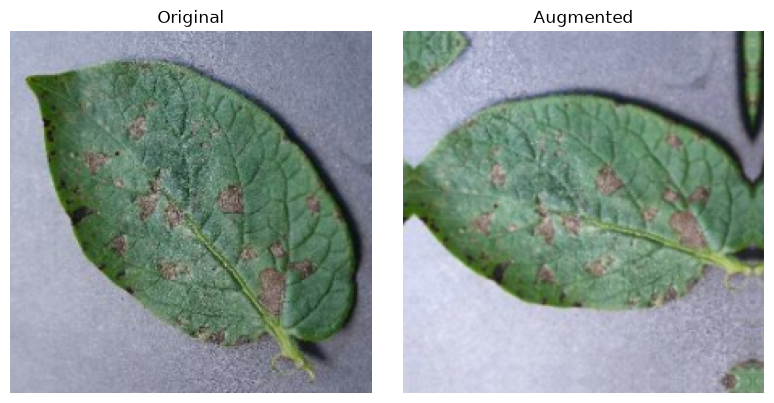

In [18]:
class_names = sorted(df["class_name"].unique())
class_to_id = {n: i for i, n in enumerate(class_names)}
NUM_CLASSES = len(class_names)
for part in (train_df, val_df, test_df):
    part["label"] = part["class_name"].map(class_to_id)
print("Number of classes:", NUM_CLASSES)
for i, n in enumerate(class_names):
    print(i, n)

def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return tf.cast(img, tf.float32), label          # raw 0-255 pixels; every model rescales internally

def create_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((dataframe["filepath"].values, dataframe["label"].values))
    if training:
        ds = ds.shuffle(len(dataframe), seed=SEED)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

# Mild, realistic augmentation (no hue shifts: colour is diagnostic for disease)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.10),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomBrightness(0.15, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.15),
], name="augmentation")

# sqrt-dampened "balanced" class weights so rare classes (e.g. Potato healthy) count more, but not extremely
y_train = train_df["label"].values
balanced = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = {i: float(w) ** 0.5 for i, w in enumerate(balanced)}
print("Class weights:", {class_names[i]: round(w, 2) for i, w in class_weight.items()})

images, labels = next(iter(train_ds))
aug = data_augmentation(images[:1], training=True)[0]
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(images[0].numpy().astype("uint8")); plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(tf.clip_by_value(aug, 0, 255).numpy().astype("uint8")); plt.title("Augmented"); plt.axis("off")
plt.tight_layout(); plt.show()

## 5. Model builders

All three models share the same contract (the web app relies on it): **input = raw RGB pixels 0-255, 224x224**, augmentation and
rescaling are inside the model, a layer named `gradcam_layer` exposes the last feature map for Grad-CAM, output = softmax over the classes.

In [19]:
def build_model(kind):
    weights = "imagenet" if USE_PRETRAINED else None
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)
    base = None
    if kind == "cnn_baseline":
        x = tf.keras.layers.Rescaling(1.0 / 255)(x)
        for filters in (32, 64):
            x = tf.keras.layers.Conv2D(filters, 3, activation="relu")(x)
            x = tf.keras.layers.MaxPooling2D()(x)
        x = tf.keras.layers.Conv2D(128, 3, activation="relu")(x)
    elif kind == "mobilenetv2":
        x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1)(x)       # MobileNetV2 expects [-1, 1]
        base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights=weights)
        base.trainable = False
        x = base(x, training=False)
    elif kind == "efficientnetb0":                                      # Keras EfficientNet expects raw 0-255
        base = tf.keras.applications.EfficientNetB0(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights=weights)
        base.trainable = False
        x = base(x, training=False)
    else:
        raise ValueError(kind)
    x = tf.keras.layers.Activation("linear", name="gradcam_layer")(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3 if kind == "cnn_baseline" else 0.2)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs, name=kind), base

def fit_model(model, name, epochs, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7),
        tf.keras.callbacks.ModelCheckpoint(str(CKPT_DIR / f"{name}.keras"), monitor="val_accuracy", save_best_only=True),
    ]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, class_weight=class_weight)

def macro_f1(y_true, y_pred):
    return float(precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[2])

y_val = val_df["label"].values

## 6. Compare models on the VALIDATION set (the test set is not touched here)

In [20]:
KINDS = ["cnn_baseline", "mobilenetv2", "efficientnetb0"]
models, histories, comparison = {}, {}, []

for kind in KINDS:
    print(f"\n=== Training {kind} ===")
    model, base = build_model(kind)
    histories[kind] = [fit_model(model, kind, EPOCHS_HEAD, 1e-3)]
    models[kind] = (model, base)

    val_probs = model.predict(val_ds, verbose=0)
    xb, _ = next(iter(val_ds))
    model.predict(xb, verbose=0)
    t0 = time.time(); model.predict(xb, verbose=0); ms = (time.time() - t0) / len(xb) * 1000
    comparison.append({"model": kind, "val_accuracy": round(float(accuracy_score(y_val, val_probs.argmax(1))), 4),
                       "val_macro_f1": round(macro_f1(y_val, val_probs.argmax(1)), 4),
                       "parameters": int(model.count_params()), "latency_ms_per_image": round(ms, 1)})

comparison_df = pd.DataFrame(comparison)
display(comparison_df)
best_kind = comparison_df.sort_values("val_macro_f1", ascending=False).iloc[0]["model"]
print("\nSelected on validation macro-F1:", best_kind)


=== Training cnn_baseline ===


c:\Users\user\Music\plantguard-ai\plantguard-ai\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.0571 - loss: 2.7177 - val_accuracy: 0.0741 - val_loss: 2.7033 - learning_rate: 0.0010

=== Training mobilenetv2 ===


c:\Users\user\Music\plantguard-ai\plantguard-ai\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.1397 - loss: 2.6634 - val_accuracy: 0.3259 - val_loss: 2.0740 - learning_rate: 0.0010

=== Training efficientnetb0 ===
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 14s 1us/step


c:\Users\user\Music\plantguard-ai\plantguard-ai\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 69s 2s/step - accuracy: 0.1857 - loss: 2.5387 - val_accuracy: 0.3926 - val_loss: 2.1872 - learning_rate: 0.0010


,model,val_accuracy,val_macro_f1,parameters,latency_ms_per_image
0,cnn_baseline,0.0741,0.0176,95183,24.8
1,mobilenetv2,0.3259,0.2891,2277199,33.8
2,efficientnetb0,0.3926,0.3748,4068786,93.9



Selected on validation macro-F1: efficientnetb0


## 7. Fine-tune the selected model
Top backbone layers are unfrozen at a low learning rate (BatchNorm layers stay frozen). If fine-tuning does not improve validation macro-F1, the head-only weights are kept.


=== Fine-tuning efficientnetb0 (last 30 backbone layers) ===


c:\Users\user\Music\plantguard-ai\plantguard-ai\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 123s 4s/step - accuracy: 0.3794 - loss: 2.1774 - val_accuracy: 0.4370 - val_loss: 2.1200 - learning_rate: 1.0000e-05
Validation macro-F1: before 0.3748 -> after 0.4218


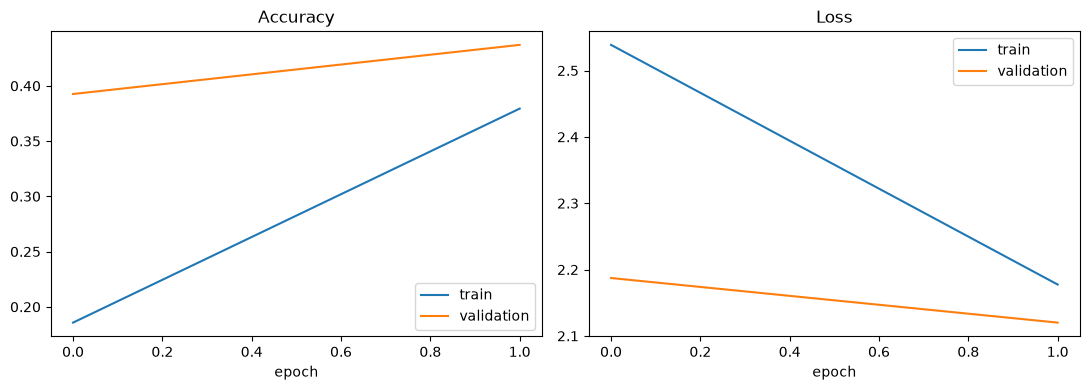

Final train accuracy 0.3794 | validation accuracy 0.4370 | gap -0.0577


In [21]:
final_model, base = models[best_kind]
before_f1 = macro_f1(y_val, final_model.predict(val_ds, verbose=0).argmax(1))
fine_tuned = False
if base is not None:
    saved_weights = final_model.get_weights()
    base.trainable = True
    for layer in base.layers[:-FINETUNE_LAYERS]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    print(f"\n=== Fine-tuning {best_kind} (last {FINETUNE_LAYERS} backbone layers) ===")
    histories[best_kind].append(fit_model(final_model, best_kind + "_finetuned", EPOCHS_FINETUNE, 1e-5))
    after_f1 = macro_f1(y_val, final_model.predict(val_ds, verbose=0).argmax(1))
    print(f"Validation macro-F1: before {before_f1:.4f} -> after {after_f1:.4f}")
    if after_f1 >= before_f1:
        fine_tuned = True
    else:
        final_model.set_weights(saved_weights)
        print("Fine-tuning did not help on validation -> kept the head-only weights.")

# ---- training curves + overfitting check ----
hist = {k: sum((h.history[k] for h in histories[best_kind]), []) for k in ("accuracy", "val_accuracy", "loss", "val_loss")}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["accuracy"], label="train"); ax[0].plot(hist["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["loss"], label="train"); ax[1].plot(hist["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=130); plt.show()
gap = hist["accuracy"][-1] - hist["val_accuracy"][-1]
print(f"Final train accuracy {hist['accuracy'][-1]:.4f} | validation accuracy {hist['val_accuracy'][-1]:.4f} | gap {gap:+.4f}")

## 8. Final evaluation on the held-out TEST set (done once)

TEST  n=135  accuracy=0.4222  macro precision=0.4391  macro recall=0.4222  macro F1=0.3852


,class,precision,recall,f1,support
0,Pepper__bell___Bacterial_spot,0.5000,0.5556,0.5263,9
1,Pepper__bell___healthy,0.7143,0.5556,0.6250,9
2,Potato___Early_blight,0.7500,1.0000,0.8571,9
3,Potato___Late_blight,0.5000,0.7778,0.6087,9
4,Potato___healthy,0.7778,0.7778,0.7778,9
5,Tomato_Bacterial_spot,0.0000,0.0000,0.0000,9
6,Tomato_Early_blight,0.0000,0.0000,0.0000,9
7,Tomato_Late_blight,1.0000,0.1111,0.2000,9
8,Tomato_Leaf_Mold,0.1250,0.1111,0.1176,9
9,Tomato_Septoria_leaf_spot,0.1875,0.3333,0.2400,9


Note: classes with very few test images (e.g. Potato healthy) have noisy per-class metrics.


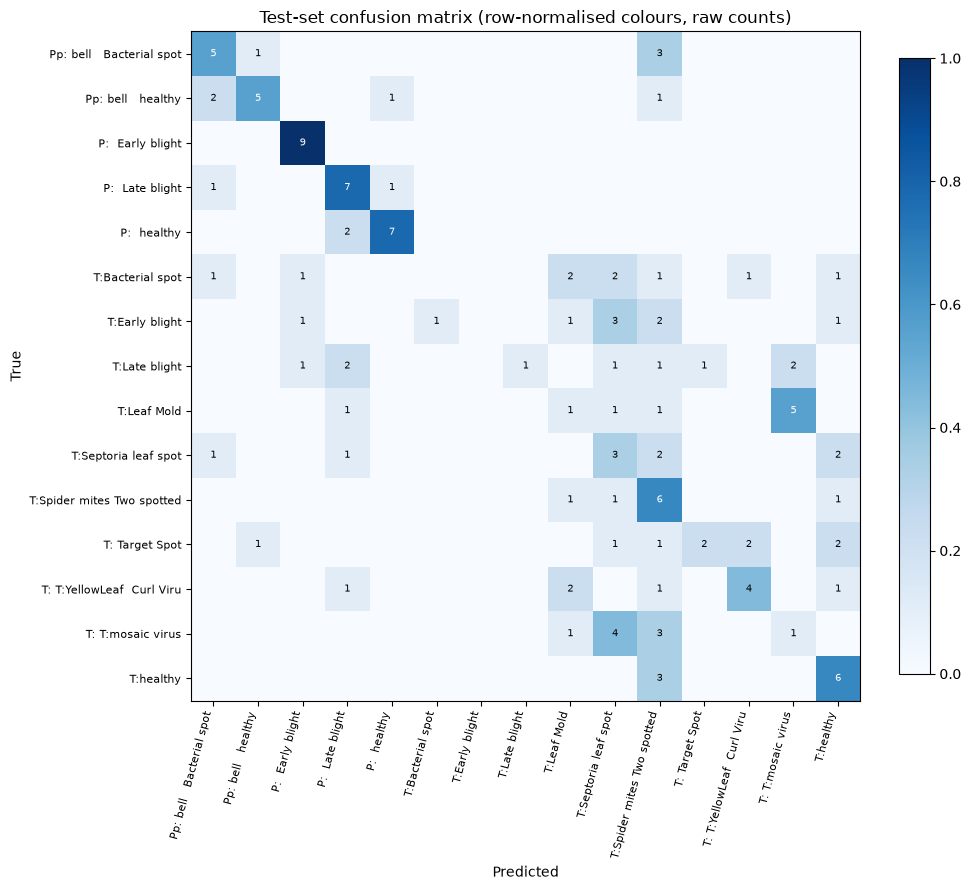

In [22]:
y_test = test_df["label"].values
test_probs = final_model.predict(test_ds, verbose=0)
y_pred = test_probs.argmax(1)

acc = float(accuracy_score(y_test, y_pred))
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
report = classification_report(y_test, y_pred, labels=list(range(NUM_CLASSES)), target_names=class_names,
                               output_dict=True, zero_division=0)
cm = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))

print(f"TEST  n={len(y_test)}  accuracy={acc:.4f}  macro precision={prec:.4f}  macro recall={rec:.4f}  macro F1={f1:.4f}")
per_class = pd.DataFrame([{"class": c, "precision": round(report[c]["precision"], 4), "recall": round(report[c]["recall"], 4),
                           "f1": round(report[c]["f1-score"], 4), "support": int(report[c]["support"])} for c in class_names])
display(per_class)
print("Note: classes with very few test images (e.g. Potato healthy) have noisy per-class metrics.")

cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
short = [n.replace("Tomato_", "T:").replace("Potato_", "P:").replace("Pepper_", "Pp:").replace("_", " ")[:26] for n in class_names]
ax.set_xticklabels(short, rotation=75, ha="right", fontsize=8); ax.set_yticklabels(short, fontsize=8)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Test-set confusion matrix (row-normalised colours, raw counts)")
plt.colorbar(im, fraction=0.04); plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=130); plt.show()

## 9. Confidence calibration (temperature scaling, fitted on the validation set)
So that '94% confidence' is closer to a real probability, and so the app can reject uncertain predictions.

In [23]:
def apply_temperature(probs, T):
    z = np.log(np.clip(probs, 1e-12, 1)) / T
    z -= z.max(axis=1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(axis=1, keepdims=True)

def nll(T, probs, y):
    p = apply_temperature(probs, T)
    return -float(np.mean(np.log(p[np.arange(len(y)), y] + 1e-12)))

def ece(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    edges, total = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return float(total)

val_probs = final_model.predict(val_ds, verbose=0)
T = float(minimize_scalar(lambda t: nll(t, val_probs, y_val), bounds=(0.3, 5.0), method="bounded").x)
test_cal = apply_temperature(test_probs, T)
print(f"Temperature T = {T:.3f}")
print(f"Test ECE before {ece(test_probs, y_test):.4f} -> after {ece(test_cal, y_test):.4f}  (lower is better)")

val_cal = apply_temperature(val_probs, T)
coverage_rows = []
for thr in (0.5, 0.6, 0.7, 0.8, 0.9):
    mv, mt = val_cal.max(1) >= thr, test_cal.max(1) >= thr
    coverage_rows.append({"threshold": thr, "val_coverage": round(float(mv.mean()), 4),
                 "val_accuracy_on_kept": round(float((val_cal.argmax(1)[mv] == y_val[mv]).mean()), 4) if mv.any() else None,
                 "test_coverage": round(float(mt.mean()), 4),
                 "test_accuracy_on_kept": round(float((test_cal.argmax(1)[mt] == y_test[mt]).mean()), 4) if mt.any() else None})
coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df)
print(f"The app refuses to diagnose below {LOW_CONF_THRESHOLD:.0%} calibrated confidence (change LOW_CONF_THRESHOLD above if needed).")

Temperature T = 0.307
Test ECE before 0.2662 -> after 0.1156  (lower is better)


,threshold,val_coverage,val_accuracy_on_kept,test_coverage,test_accuracy_on_kept
0,0.5,0.3704,0.7000,0.3259,0.7045
1,0.6,0.2148,0.7931,0.2000,0.8519
2,0.7,0.1259,0.8235,0.1111,0.8000
3,0.8,0.0667,0.8889,0.0667,0.7778
4,0.9,0.0296,1.0000,0.0074,1.0000


The app refuses to diagnose below 60% calibrated confidence (change LOW_CONF_THRESHOLD above if needed).


## 10. Save everything into `model_weights/` and verify the saved model

In [24]:
final_model.save(str(OUT_DIR / "plantguard_model.keras"))
(OUT_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2))
(OUT_DIR / "calibration.json").write_text(json.dumps(
    {"temperature": T, "low_confidence_threshold": LOW_CONF_THRESHOLD, "fitted_on": "validation set"}, indent=2))

metrics = {
    "generated": datetime.now().isoformat(timespec="seconds"),
    "tensorflow": tf.__version__, "seed": SEED, "quick_test": QUICK_TEST, "pretrained": USE_PRETRAINED,
    "selected_model": best_kind, "fine_tuned": fine_tuned,
    "dataset": dataset_report,
    "comparison_validation": comparison,
    "test": {"n": int(len(y_test)), "accuracy": round(acc, 4), "macro_precision": round(float(prec), 4),
             "macro_recall": round(float(rec), 4), "macro_f1": round(float(f1), 4)},
    "per_class": per_class.to_dict("records"),
    "confusion_matrix": {"labels": class_names, "matrix": cm.tolist()},
    "overfitting": {"final_train_accuracy": round(hist["accuracy"][-1], 4),
                    "final_val_accuracy": round(hist["val_accuracy"][-1], 4), "gap": round(gap, 4)},
    "calibration": {"temperature": round(T, 4), "test_ece_before": round(ece(test_probs, y_test), 4),
                    "test_ece_after": round(ece(test_cal, y_test), 4), "coverage_table": coverage_rows},
    "figures": ["confusion_matrix.png", "training_curves.png"],
    "notes": ["Test set used once, after model selection on validation data.",
              "PlantVillage images are lab-style; field/phone-photo accuracy is expected to be lower and must be measured separately."],
}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))

# ---- verify: reload from disk, predictions must match, Grad-CAM layer must exist ----
reloaded = tf.keras.models.load_model(str(OUT_DIR / "plantguard_model.keras"), compile=False)
xb, _ = next(iter(test_ds))
diff = float(np.abs(reloaded.predict(xb, verbose=0) - final_model.predict(xb, verbose=0)).max())
reloaded.get_layer("gradcam_layer")
assert diff < 1e-3, f"reloaded model differs from the trained model (max diff {diff})"
print(f"Reload check OK (max prediction difference {diff:.2e}); Grad-CAM layer present.")

if QUICK_TEST:
    print("\nQUICK_TEST was ON: these results are meaningless. Set QUICK_TEST = False and run again for the real model.")

print("\nSaved files:")
for f in sorted(OUT_DIR.iterdir()):
    if f.is_file():
        print(f"  {f.name:28s} {f.stat().st_size / 1e6:8.2f} MB")

if ON_KAGGLE:
    archive = shutil.make_archive("/kaggle/working/plantguard_model_files", "zip", OUT_DIR)
    print("\nKAGGLE: download", archive, "from the Output tab and unzip it into plantguard-ai/model_weights/")
else:
    print("\nDone. The model is in", OUT_DIR, "- now start the web app (see README).")

Reload check OK (max prediction difference 0.00e+00); Grad-CAM layer present.

QUICK_TEST was ON: these results are meaningless. Set QUICK_TEST = False and run again for the real model.

Saved files:
  .gitkeep                         0.00 MB
  calibration.json                 0.00 MB
  class_names.json                 0.00 MB
  confusion_matrix.png             0.10 MB
  metrics.json                     0.01 MB
  plantguard_model.keras          29.18 MB
  test_split.csv                   0.03 MB
  train_split.csv                  0.14 MB
  training_curves.png              0.06 MB
  validation_split.csv             0.03 MB

Done. The model is in c:\Users\user\Music\plantguard-ai\plantguard-ai\model_weights - now start the web app (see README).
